In [1]:
# Cell 1 — Setup
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

from src.features import FEATURE_COLS
from src.models import build_lgbm_baseline, build_xgb_baseline, build_catboost_baseline
from src.signal_gate import apply_signal_gate, summarise_gate_results

# df = pd.read_csv('../features/eurusd_labelled.csv', index_col=0, parse_dates=True)
df = pd.read_csv('../features/eurusd_regime_labelled.csv', index_col=0, parse_dates=True)
print(f"Regime column present: {'regime_name' in df.columns}")
print(f"Regime distribution:\n{df['regime_name'].value_counts()}")
X = df[FEATURE_COLS]
y = df['label_binary'].astype(int)

split_idx = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Test set: {len(X_test):,} rows for gate analysis")

Regime column present: True
Regime distribution:
regime_name
ranging           14747
volatile_trend    10514
quiet_trend        5615
Name: count, dtype: int64
Test set: 6,176 rows for gate analysis


In [2]:
# Cell 2 — Train ensemble and get probabilities
from sklearn.base import BaseEstimator, ClassifierMixin

# class EnsembleClassifier(BaseEstimator, ClassifierMixin):
#     def __init__(self):
#         self.lgbm = build_lgbm_baseline()
#         self.xgb  = build_xgb_baseline()
#     def fit(self, X, y):
#         self.lgbm.fit(X, y)
#         self.xgb.fit(X, y)
#         self.classes_ = np.array([0, 1])
#         return self
#     def predict_proba(self, X):
#         lp = self.lgbm.predict_proba(X)[:, 1]
#         xp = self.xgb.predict_proba(X)[:, 1]
#         avg = 0.55 * lp + 0.45 * xp
#         return np.column_stack([1 - avg, avg])
#     def predict(self, X):
#         return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

class EnsembleClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self):
        self.lgbm = build_lgbm_baseline()
        self.xgb  = build_xgb_baseline()
        self.cat  = build_catboost_baseline()

    def fit(self, X, y):
        self.lgbm.fit(X, y)
        self.xgb.fit(X, y)
        self.cat.fit(X, y)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        lp = self.lgbm.predict_proba(X)[:, 1]
        xp = self.xgb.predict_proba(X)[:, 1]
        cp = self.cat.predict_proba(X)[:, 1]
        # LGBM leads, XGB and CatBoost support
        avg = 0.45 * lp + 0.30 * xp + 0.25 * cp
        return np.column_stack([1 - avg, avg])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

print("Training ensemble...")
ensemble = EnsembleClassifier()
ensemble.fit(X_train, y_train)
probs = ensemble.predict_proba(X_test)[:, 1]
print("Done.")

Training ensemble...
Done.


In [3]:
# # Cell 3 — Apply signal gate and summarise
# gate_results = apply_signal_gate(df.iloc[split_idx:], probs, FEATURE_COLS)
# summarise_gate_results(gate_results, y_test.reset_index(drop=True))

# Cell 3 — Apply signal gate and summarise
# Make sure df_test has regime_name
df_test = df.iloc[split_idx:]
print(f"Regime column in test set: {'regime_name' in df_test.columns}")
print(f"Test regime distribution:\n{df_test['regime_name'].value_counts()}")

# Apply gate WITH regime awareness
gate_results = apply_signal_gate(df_test, probs, FEATURE_COLS)
summarise_gate_results(gate_results, y_test.reset_index(drop=True))


Regime column in test set: True
Test regime distribution:
regime_name
ranging           4344
volatile_trend    1270
quiet_trend        562
Name: count, dtype: int64

  Signal Gate Summary
  Total bars evaluated : 6,176
  Signals passed gate  : 592  (9.6%)
  Signals blocked      : 5,584  (90.4%)

  Blocked by reason:
    low_conf_ranging               : 3,613  (58.5%)
    low_conf_volatile_trend        : 1,086  (17.6%)
    low_conf_quiet_trend           : 477  (7.7%)
    adx_too_low                    : 295  (4.8%)
    vix_extreme                    : 113  (1.8%)

  Accuracy on gated signals : 81.08%
  Accuracy on all signals   : 60.57%

  Gate lift                 : +20.51%


In [4]:
# Cell 4 — Accuracy at different confidence thresholds
thresholds = [0.55, 0.58, 0.60, 0.62, 0.65, 0.68, 0.70]
print("Confidence threshold sweep:")
print("-" * 55)
print(f"  {'Threshold':>12} | {'Signals':>8} | {'% of total':>10} | {'Accuracy':>9}")
print("-" * 55)

for t in thresholds:
    mask = (probs >= t) | (probs <= (1 - t))
    count = mask.sum()
    if count >= 10:
        acc = ((probs[mask] >= 0.5).astype(int) == y_test.values[mask]).mean()
        pct = count / len(probs) * 100
        print(f"  {t:>12.2f} | {count:>8,} | {pct:>9.1f}% | {acc*100:>8.2f}%")
    else:
        print(f"  {t:>12.2f} | {count:>8,} | {'<10 signals — skip':>22}")
print("-" * 55)
print("Find the threshold where accuracy crosses 70% with enough signals remaining.")

Confidence threshold sweep:
-------------------------------------------------------
     Threshold |  Signals | % of total |  Accuracy
-------------------------------------------------------
          0.55 |    3,331 |      53.9% |    68.90%
          0.58 |    1,655 |      26.8% |    75.35%
          0.60 |    1,100 |      17.8% |    81.45%
          0.62 |      968 |      15.7% |    82.75%
          0.65 |      773 |      12.5% |    84.48%
          0.68 |      540 |       8.7% |    87.59%
          0.70 |      418 |       6.8% |    91.15%
-------------------------------------------------------
Find the threshold where accuracy crosses 70% with enough signals remaining.


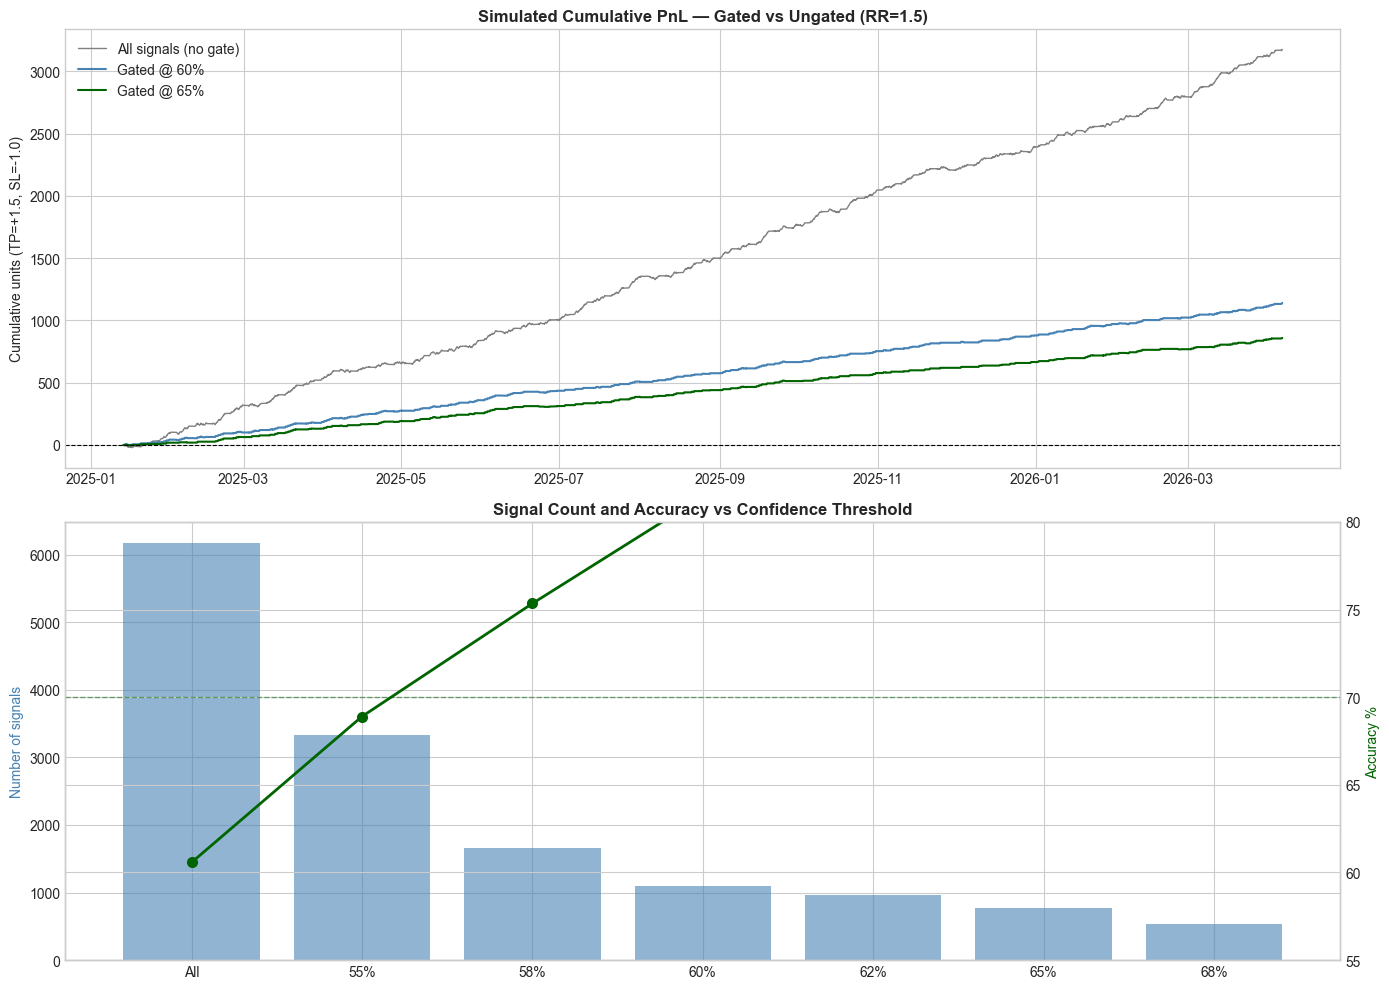

In [5]:
# Cell 5 — PnL simulation (gated vs ungated)
# Simple simulation: +1.5 for correct, -1.0 for wrong, 0 for blocked
# TP/SL ratio of 1.5 matches our triple-barrier labels

def simulate_cumulative_pnl(probs, y_true, threshold=0.60, rr=1.5):
    pnl = []
    for p, actual in zip(probs, y_true.values):
        hc = (p >= threshold) or (p <= 1 - threshold)
        if not hc:
            pnl.append(0.0)
            continue
        pred = 1 if p >= 0.5 else 0
        pnl.append(rr if pred == actual else -1.0)
    return pd.Series(pnl, index=y_true.index)

# Ungated
pnl_ungated = pd.Series(
    [1.5 if (int(p >= 0.5) == a) else -1.0
     for p, a in zip(probs, y_test.values)],
    index=y_test.index
)

# Gated at 0.60
pnl_gated_60 = simulate_cumulative_pnl(probs, y_test, threshold=0.60)

# Gated at 0.65
pnl_gated_65 = simulate_cumulative_pnl(probs, y_test, threshold=0.65)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Cumulative PnL curves
axes[0].plot(y_test.index, pnl_ungated.cumsum(),    label='All signals (no gate)', color='gray',      linewidth=1.0)
axes[0].plot(y_test.index, pnl_gated_60.cumsum(),   label='Gated @ 60%',           color='steelblue', linewidth=1.5)
axes[0].plot(y_test.index, pnl_gated_65.cumsum(),   label='Gated @ 65%',           color='darkgreen', linewidth=1.5)
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title('Simulated Cumulative PnL — Gated vs Ungated (RR=1.5)', fontweight='bold')
axes[0].set_ylabel('Cumulative units (TP=+1.5, SL=-1.0)')
axes[0].legend(fontsize=10)

# Signal count per threshold
labels_t = ['All', '55%', '58%', '60%', '62%', '65%', '68%']
thresholds_t = [0.0, 0.55, 0.58, 0.60, 0.62, 0.65, 0.68]
counts = []
accs   = []
for t in thresholds_t:
    if t == 0:
        mask = np.ones(len(probs), dtype=bool)
    else:
        mask = (probs >= t) | (probs <= (1-t))
    counts.append(mask.sum())
    if mask.sum() >= 10:
        accs.append(((probs[mask] >= 0.5).astype(int) == y_test.values[mask]).mean() * 100)
    else:
        accs.append(np.nan)

ax2 = axes[1]
bars = ax2.bar(labels_t, counts, color='steelblue', alpha=0.6, edgecolor='none')
ax2.set_ylabel('Number of signals', color='steelblue')
ax2.set_title('Signal Count and Accuracy vs Confidence Threshold', fontweight='bold')

ax3 = ax2.twinx()
ax3.plot(labels_t, accs, 'o-', color='darkgreen', linewidth=2, markersize=7, label='Accuracy %')
ax3.axhline(70, color='darkgreen', linestyle='--', alpha=0.5, linewidth=1)
ax3.set_ylabel('Accuracy %', color='darkgreen')
ax3.set_ylim(55, 80)

plt.tight_layout()
plt.savefig('../results/08_signal_gate_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

In [6]:
# Cell 6 — Final gate recommendation
print("=" * 55)
print("  Signal Gate Recommendation")
print("=" * 55)
print()

# Find optimal threshold: highest accuracy with at least 15% of signals remaining
min_signal_pct = 0.15
optimal_t = None
optimal_acc = 0

for t in [0.55, 0.58, 0.60, 0.62, 0.65]:
    mask = (probs >= t) | (probs <= (1-t))
    pct = mask.sum() / len(probs) 
    if pct >= min_signal_pct and mask.sum() >= 10:
        acc = ((probs[mask] >= 0.5).astype(int) == y_test.values[mask]).mean()
        if acc > optimal_acc:
            optimal_acc = acc
            optimal_t = t
            optimal_signals = mask.sum()

if optimal_t:
    print(f"  Optimal confidence threshold : {optimal_t}")
    print(f"  Signals passing gate         : {optimal_signals:,} ({optimal_signals/len(probs)*100:.1f}%)")
    print(f"  Expected accuracy on signals : {optimal_acc*100:.2f}%")
    print()
    print(f"  Update CONFIDENCE_THRESHOLD in src/signal_gate.py:")
    print(f"    CONFIDENCE_THRESHOLD = {optimal_t}")
print("=" * 55)
print()
print("Next step: Report this output and we move to Phase 2 macro integration.")
print("(Central bank stance encoding + rate differential feature)")

  Signal Gate Recommendation

  Optimal confidence threshold : 0.62
  Signals passing gate         : 968 (15.7%)
  Expected accuracy on signals : 82.75%

  Update CONFIDENCE_THRESHOLD in src/signal_gate.py:
    CONFIDENCE_THRESHOLD = 0.62

Next step: Report this output and we move to Phase 2 macro integration.
(Central bank stance encoding + rate differential feature)
